<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and pinned model assets](README.md)

# 01 · Rank documents, then budget the rendered context

A semantic ranking orders candidate text; it does not say how many documents will fit in a context string. We will embed a small synthetic support-note collection once, rank it by cosine similarity to one query, and select the largest complete ranking prefix whose **rendered prompt text** fits a token budget.

**Real local model; synthetic teaching documents.** Embeddings, similarity, prompt substitution and token counting use the actual VGI worker. No completion is generated and no provider credentials are needed. Similarity is not a probability of relevance, and this example has no labeled retrieval benchmark or answer-quality assessment.

## Set the complete-text budget

`TOKEN_BUDGET` accepts integers from **60 to 1000 tokens**. The default is **120**; the experiment increases only that value to **220**. It includes the instruction, query, document identifiers, separators and selected bodies in the rendered text. It excludes API message framing, tools, output tokens and provider-specific overhead, so it is not a billable-token or model-context-limit guarantee.

`QUERY_TEXT` is a nonempty English query, at most 1000 characters. Keep it fixed for the budget experiment. The embedding model and tokenizer are fixed below. Restart Kernel → Run All after editing.

In [1]:
TOKEN_BUDGET = 120  # Whole rendered-text tokens; experiment: 220
QUERY_TEXT = "I replaced my phone and cannot sign in because the old authenticator is unavailable."

In [2]:
import hashlib
import json

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display

from embedding_assets import EmbeddingAssets

assert type(TOKEN_BUDGET) is int and 60 <= TOKEN_BUDGET <= 1000
assert isinstance(QUERY_TEXT, str) and QUERY_TEXT.strip() and len(QUERY_TEXT) <= 1000
QUERY_SQL = QUERY_TEXT.replace("'", "''")
assets = EmbeddingAssets()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Source: synthetic support notes · local BGE-small-en-v1.5 (384 dimensions) · pinned ONNX assets · no completion generated",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.97))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-llm/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-llm/notebooks/pyproject.toml.

## Use the pinned worker and immutable local embedding assets

The literal Git tag resolves to `49a1f9e35edae6cb247ee0a07205c48b41833588`. Python inference and tokenizer dependencies are pinned in the command. The companion prepares approximately **67 MB** of ONNX/tokenizer assets from Hugging Face revision `aa8f8b060edb00e03bfdd08813a2949946c8ba55`, verifies every committed SHA-256, and sets the worker's model cache to those files with Hugging Face offline mode enabled. No model fallback is supplied.

The inputs below are synthetic product-support notes, not instructions for a real service. IDs and raw bodies remain visible. NULL and whitespace-only rows stay in the source table so their exclusion from ranking is explicit.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'llm' (
 TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-llm@v0.4.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with fastembed==0.9.1 --with onnxruntime==1.31.1 --with tiktoken==0.14.0 --with pyarrow==25.0.1 --with numpy==2.5.4 vgi-llm-worker'
);
CREATE TABLE documents(doc_id VARCHAR,title VARCHAR,body VARCHAR);
INSERT INTO documents VALUES
 ('D01','Lost authenticator','If an authenticator device is lost, the example service offers saved recovery codes. Without a recovery code, contact the account administrator for the documented recovery process.'),
 ('D02','Password reset','Password reset links expire after fifteen minutes. Request a new link from the sign-in page. Resetting a password does not remove the account multi-factor requirement.'),
 ('D03','New phone enrollment','Before replacing a phone, enroll the new authenticator and verify a test sign-in. Keep recovery codes separately. Removing the old device should follow successful enrollment.'),
 ('D04','Administrator recovery','Account administrators review identity evidence before resetting a member authentication method. The fictional service records that action in its audit log and requires enrollment of a replacement method.'),
 ('D05','Invoice download','Billing administrators can download monthly invoices from the billing page. Invoice exports contain the subscription period, account reference and itemized charges.'),
 ('D06','Email notifications','Notification preferences control product updates and weekly summaries. Security notices about sign-in events remain enabled separately from marketing messages.'),
 ('D07','CSV export','Data exports use UTF-8 CSV with a header row. Large exports are split into numbered files. A download link expires after one day.'),
 ('D08','Browser session','A browser session can expire after inactivity. Signing in again restores access. A remembered session is different from a saved password or an enrolled authenticator.'),
 ('D09','Missing body',NULL),('D10','Blank body','   ');
CREATE TABLE embedded_documents AS
SELECT *,llm.main.ai_embed(body,'BAAI/bge-small-en-v1.5') AS embedding FROM documents;
CREATE TABLE embedded_query AS
SELECT '{{QUERY_SQL}}' AS query_text,
 llm.main.ai_embed('{{QUERY_SQL}}','BAAI/bge-small-en-v1.5') AS embedding;

,Count


In [4]:
source = con.execute("SELECT * FROM documents ORDER BY doc_id").df()
vectors = con.execute("SELECT doc_id,embedding FROM embedded_documents ORDER BY doc_id").fetchall()
assert source.doc_id.is_unique
for doc_id, vector in vectors:
    body = source.loc[source.doc_id.eq(doc_id), "body"].iloc[0]
    if body is None or not body.strip():
        assert vector is None
    else:
        assert vector is not None and len(vector) == 384 and np.isfinite(vector).all()
assert con.execute(
    "SELECT abs(llm.main.ai_similarity(embedding,embedding)-1)<1e-5 FROM embedded_query"
).fetchone()[0]
fingerprint = hashlib.sha256(json.dumps(vectors, default=str).encode()).hexdigest()
nonempty = sum(vector is not None for _, vector in vectors)
prose(
    f"**{len(source)} source rows**, **{nonempty} usable document vectors**, and **{len(source) - nonempty} unavailable embeddings** for missing/blank inputs. Every usable vector has **384 finite values**; self-similarity agrees with 1 within numerical tolerance. Document-vector fingerprint: `{fingerprint}`. Model asset revision: `{assets.manifest['revision']}`. Charting and budget changes reuse these materialized vectors."
)

**10 source rows**, **8 usable document vectors**, and **2 unavailable embeddings** for missing/blank inputs. Every usable vector has **384 finite values**; self-similarity agrees with 1 within numerical tolerance. Document-vector fingerprint: `953a14a2297ad8214ec552155b514415bd1472fbd68a556ed0dc2415c41289fc`. Model asset revision: `aa8f8b060edb00e03bfdd08813a2949946c8ba55`. Charting and budget changes reuse these materialized vectors.

## Rank the complete usable collection before applying a budget

Cosine similarity compares the query vector with each document vector. Sort descending, then by ID for deterministic ties. Missing embeddings do not receive a zero score and cannot enter the ranking. The numerical scale describes this model and this text collection; a high score does not establish factual correctness, policy applicability or that a document answers the query.

In [5]:
%%sql
CREATE TABLE scored AS
SELECT d.doc_id,d.title,d.body,llm.main.ai_similarity(d.embedding,q.embedding) AS cosine
FROM embedded_documents d CROSS JOIN embedded_query q WHERE d.embedding IS NOT NULL;
CREATE TABLE ranked AS
SELECT *,row_number() OVER (ORDER BY cosine DESC,doc_id) AS relevance_rank FROM scored;

,Count


In [6]:
%%sql ranking <<
SELECT relevance_rank,doc_id,title,round(cosine,5) AS cosine FROM ranked ORDER BY relevance_rank;

,relevance_rank,doc_id,title,cosine
0,1,D03,New phone enrollment,0.83507
1,2,D01,Lost authenticator,0.72949
2,3,D08,Browser session,0.61950
3,4,D02,Password reset,0.60985
4,5,D04,Administrator recovery,0.52413
5,6,D06,Email notifications,0.51926
6,7,D05,Invoice download,0.42956
7,8,D07,CSV export,0.42572


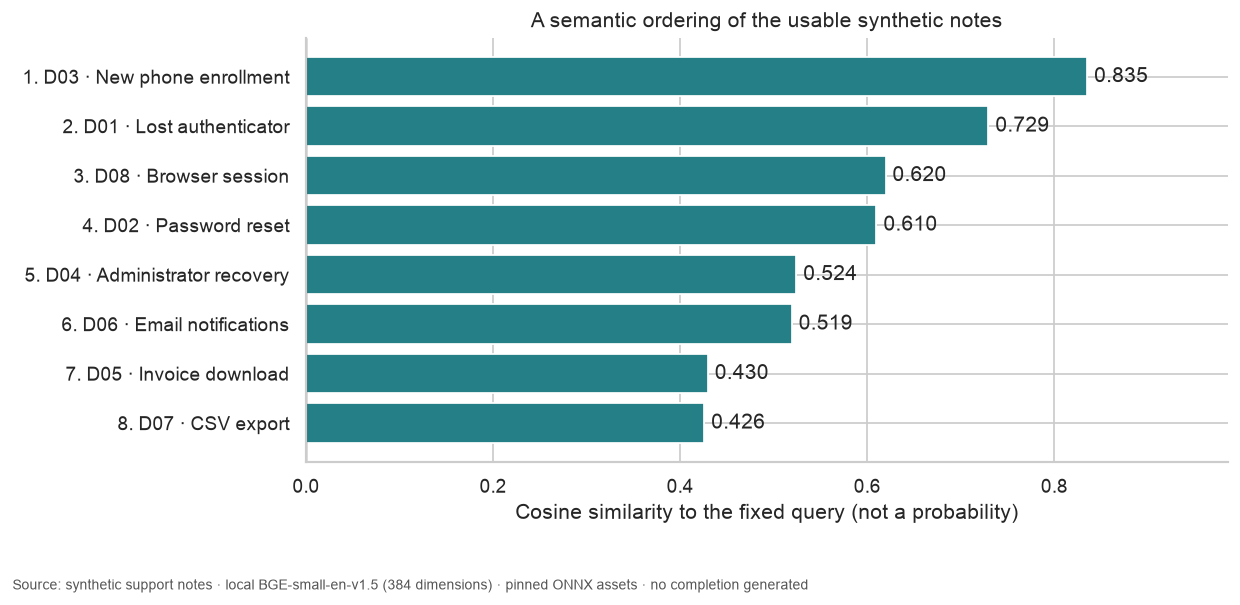

The first ranked note is **D03 · New phone enrollment**, with cosine **0.83507**. This is an observed ordering from the pinned model. The budget stage will preserve that ordering rather than optimize a different subset.

For this fixed query, the top-ranked note discusses enrollment **before replacing a phone**, while the query describes a phone **already replaced**. That timing difference needs review even though the embedding score is high. The ranking alone does not establish applicability.

In [7]:
display(ranking)
assert len(ranking) == nonempty and ranking.doc_id.is_unique
assert ranking.cosine.between(-1.00001, 1.00001).all()
assert ranking.cosine.is_monotonic_decreasing
fig, ax = plt.subplots(figsize=(10, 5))
labels = [f"{r.relevance_rank}. {r.doc_id} · {r.title}" for r in ranking.itertuples()]
bars = ax.barh(labels, ranking.cosine, color="#247f86")
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.invert_yaxis()
ax.axvline(0, color="#555555", linewidth=0.8)
ax.set(
    xlabel="Cosine similarity to the fixed query (not a probability)",
    title="A semantic ordering of the usable synthetic notes",
    xlim=(min(0, ranking.cosine.min() - 0.05), min(1.1, ranking.cosine.max() + 0.15)),
)
finish(fig)
first = ranking.iloc[0]
prose(
    f"The first ranked note is **{first.doc_id} · {first.title}**, with cosine **{first.cosine:.5f}**. This is an observed ordering from the pinned model. The budget stage will preserve that ordering rather than optimize a different subset."
)
if (
    QUERY_TEXT == "I replaced my phone and cannot sign in because the old authenticator is unavailable."
    and first.doc_id == "D03"
):
    prose(
        "For this fixed query, the top-ranked note discusses enrollment **before replacing a phone**, while the query describes a phone **already replaced**. That timing difference needs review even though the embedding score is high. The ranking alone does not establish applicability."
    )

## Render every complete prefix and count its actual text tokens

Build prefixes of size 0 through the full ranking. Size 0 still contains the instruction and query. `prompt()` performs safe substitution without a model call. `ai_count_tokens(..., 'openai/gpt-4o')` selects tiktoken's `o200k_base` encoding; the model label selects a tokenizer only and does not call OpenAI.

Count the **complete rendered string**, including identifiers and separators. Summing independent body counts would omit surrounding text and can differ because token boundaries depend on the string. Documents are never truncated. This is a ranking-prefix policy, not a knapsack optimization or a guarantee that additional notes improve an answer.

In [8]:
%%sql
CREATE TABLE prefix_contexts AS
WITH sizes AS (SELECT 0::BIGINT AS prefix_size UNION ALL SELECT relevance_rank FROM ranked)
SELECT s.prefix_size,
 coalesce(string_agg('['||r.doc_id||'] '||r.body,chr(10)||chr(10) ORDER BY r.relevance_rank),'') AS context_text
FROM sizes s LEFT JOIN ranked r ON r.relevance_rank<=s.prefix_size GROUP BY s.prefix_size;
CREATE TABLE rendered_prompts AS
SELECT prefix_size,llm.main.prompt(
 'Use only these synthetic notes. If they do not answer the question, say so.'||chr(10)||
 'Question: {}'||chr(10)||chr(10)||'Context:'||chr(10)||'{}',
 '{{QUERY_SQL}}',context_text) AS rendered_text
FROM prefix_contexts;
CREATE TABLE counted_prefixes AS
SELECT *,llm.main.ai_count_tokens(rendered_text,'openai/gpt-4o') AS text_tokens
FROM rendered_prompts;

,Count


In [9]:
%%sql prefixes <<
SELECT prefix_size,text_tokens,text_tokens<={{TOKEN_BUDGET}} AS fits_budget
FROM counted_prefixes ORDER BY prefix_size;

,prefix_size,text_tokens,fits_budget
0,0,37,True
1,1,71,True
2,2,105,True
3,3,137,False
4,4,171,False
5,5,204,False
6,6,229,False
7,7,257,False
8,8,288,False


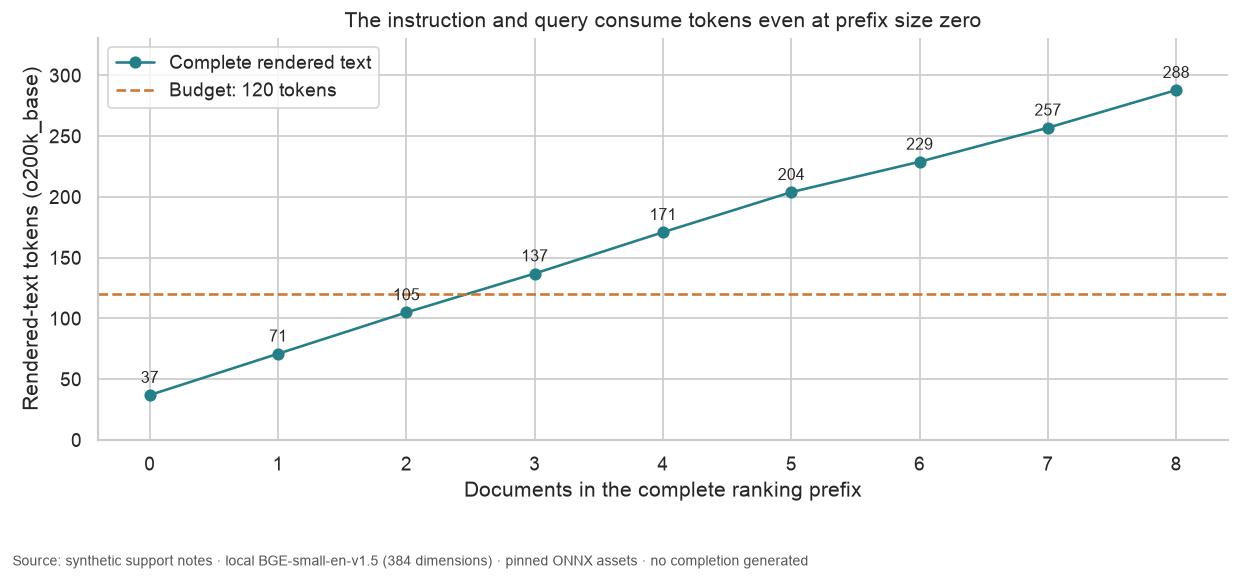

In [10]:
display(prefixes)
assert len(prefixes) == nonempty + 1 and prefixes.prefix_size.is_unique
assert prefixes.text_tokens.notna().all() and prefixes.text_tokens.gt(0).all()
assert prefixes.text_tokens.is_monotonic_increasing
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(
    prefixes.prefix_size, prefixes.text_tokens, marker="o", color="#247f86", label="Complete rendered text"
)
ax.axhline(TOKEN_BUDGET, color="#cc7832", linestyle="--", label=f"Budget: {TOKEN_BUDGET} tokens")
for r in prefixes.itertuples():
    ax.annotate(
        str(r.text_tokens),
        (r.prefix_size, r.text_tokens),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
ax.set(
    xlabel="Documents in the complete ranking prefix",
    ylabel="Rendered-text tokens (o200k_base)",
    title="The instruction and query consume tokens even at prefix size zero",
    ylim=(0, max(TOKEN_BUDGET, prefixes.text_tokens.max()) * 1.15),
)
ax.set_xticks(prefixes.prefix_size)
ax.legend()
finish(fig)

## Select the largest fitting prefix and inspect what it contains

The SQL chooses the largest prefix within the visible budget. If even size 0 does not fit, there is no valid result; that is distinct from a zero-document context that fits. Keep the selected text visible for inspection. It remains a prompt candidate, not an answer or an executed provider request.

In [11]:
%%sql selected <<
SELECT prefix_size,text_tokens,{{TOKEN_BUDGET}}-text_tokens AS unused_text_tokens,rendered_text
FROM counted_prefixes WHERE text_tokens<={{TOKEN_BUDGET}}
ORDER BY prefix_size DESC LIMIT 1;

In [12]:
display(selected)
assert len(selected) <= 1
if len(selected):
    chosen = selected.iloc[0]
    assert chosen.text_tokens <= TOKEN_BUDGET and chosen.unused_text_tokens >= 0
    later = prefixes[prefixes.prefix_size > chosen.prefix_size]
    assert later.text_tokens.gt(TOKEN_BUDGET).all()
    ids = ranking.loc[ranking.relevance_rank <= chosen.prefix_size, "doc_id"].tolist()
    prose(
        f"A **{TOKEN_BUDGET}-token text budget** retains **{int(chosen.prefix_size)} documents** ({', '.join(ids) or 'none'}). The complete string uses **{int(chosen.text_tokens)} tokens**, leaving **{int(chosen.unused_text_tokens)} text tokens** under this rule. No larger complete prefix fits. The unused amount is not an output-token allowance or a billing estimate."
    )
    display(Markdown("```text\n" + chosen.rendered_text + "\n```"))
else:
    prose(
        f"**No prefix fits:** the instruction and query alone use **{int(prefixes.text_tokens.iloc[0])} tokens**, exceeding the **{TOKEN_BUDGET}-token** text budget. No document count is fabricated and no completion is attempted."
    )

,prefix_size,text_tokens,unused_text_tokens,rendered_text
0,2,105,15,Use only these synthetic notes. If they do not...


A **120-token text budget** retains **2 documents** (D03, D01). The complete string uses **105 tokens**, leaving **15 text tokens** under this rule. No larger complete prefix fits. The unused amount is not an output-token allowance or a billing estimate.

```text
Use only these synthetic notes. If they do not answer the question, say so.
Question: I replaced my phone and cannot sign in because the old authenticator is unavailable.

Context:
[D03] Before replacing a phone, enroll the new authenticator and verify a test sign-in. Keep recovery codes separately. Removing the old device should follow successful enrollment.

[D01] If an authenticator device is lost, the example service offers saved recovery codes. Without a recovery code, contact the account administrator for the documented recovery process.
```

## Experiment: increase only the text budget

Change `TOKEN_BUDGET` from **120 to 220** in a separate executed copy. Predict that the selected prefix cannot shrink. Compare the number of included documents, exact token count, unused text budget and newly included note IDs. The query, vector fingerprint, ranking, model revision and prefix token-count curve should remain unchanged. Restore **120** afterwards.

A larger context can include more weakly related material. This notebook does not test generation, answer accuracy, groundedness, calibrated relevance or provider cost. Such claims would require a separate evaluation with representative questions, labeled evidence and an explicit completion model.

In [13]:
con.close()
assets.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)